<a href="https://colab.research.google.com/github/beherapriyanka186-netizen/python_nist/blob/main/EMOTION_DETECTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CREATE THE FOLDER STRUCTURE

In [1]:

import os

# Main project folder
PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"

# Create all required folders
folders = [
    "data",
    "data/processed",
    "src",
    "models",
    "outputs",
    "reports",
    "notebooks"
]

for folder in folders:
    path = os.path.join(PROJECT_DIR, folder)
    os.makedirs(path, exist_ok=True)
    print("Created:", path)

print("\nStep 1 completed successfully!")
print("Project location:", PROJECT_DIR)


Created: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/data
Created: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/data/processed
Created: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/src
Created: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/models
Created: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/outputs
Created: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/reports
Created: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/notebooks

Step 1 completed successfully!
Project location: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL


Install Libraries

In [2]:

# STEP 2: Install and Import Required Libraries

%pip install -q datasets nltk scikit-learn seaborn pandas numpy matplotlib tensorflow joblib

# 1. Import system libraries
import os
import re
import json
import warnings

# 2. Import data handling libraries
import numpy as np
import pandas as pd

# 3. Import NLP libraries
import nltk

# 4. Import dataset library
from datasets import load_dataset

# 5. Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 6. Import deep learning libraries
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    Bidirectional,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

# 7. Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# 8. Import model-saving library
import joblib

# 9. Configure warnings and random seeds
warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

# 10. Download NLTK resources if needed
nltk.download("punkt", quiet=True)

print("All required libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("TensorFlow version:", tf.__version__)
print("Step 2 completed successfully!")


All required libraries imported successfully!
NumPy version: 2.1.3
Pandas version: 2.2.3
TensorFlow version: 2.21.0
Step 2 completed successfully!


Dataset Load

Loading Emotion dataset...


README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]


Dataset splits:
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Dataset shapes:
Training data: (16000, 2)
Validation data: (2000, 2)
Testing data: (2000, 2)

First five records:
                                                text  label
0                            i didnt feel humiliated      0
1  i can go from feeling so hopeless to so damned...      0
2   im grabbing a minute to post i feel greedy wrong      3
3  i am ever feeling nostalgic about the fireplac...      2
4                               i am feeling grouchy      3

Column names:
['text', 'label']

Missing values:
text     0
label    0
dtype: int64

Emotion categories:
['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

Emotion distribution in training data:
emotion
joy         

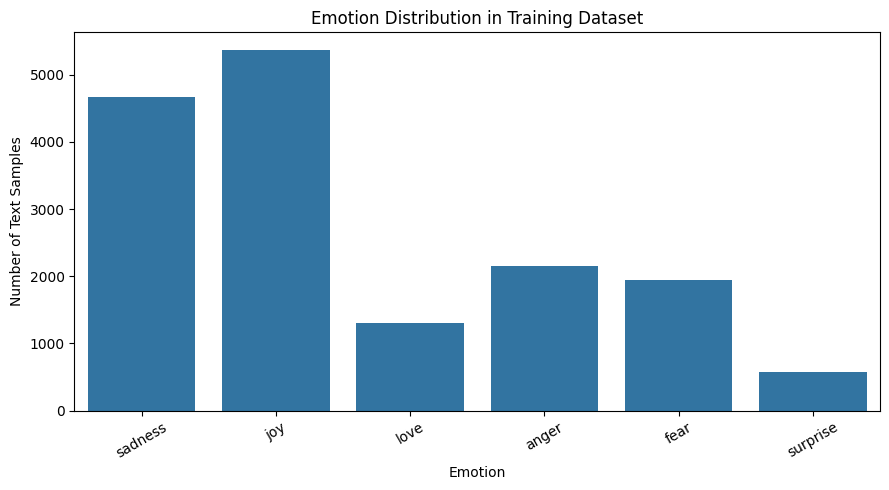


Dataset CSV files saved successfully!
Emotion distribution graph saved at: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/outputs/emotion_distribution.png
STEP 3 COMPLETED SUCCESSFULLY!


In [4]:

# STEP 3: Load and Explore the Emotion Dataset

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

# 1. Set the project directory
PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"
DATA_DIR = os.path.join(PROJECT_DIR, "data")

# 2. Load the dataset from Hugging Face
print("Loading Emotion dataset...")

dataset = load_dataset("dair-ai/emotion")

# 3. Display available dataset splits
print("\nDataset splits:")
print(dataset)

# 4. Convert the splits into Pandas DataFrames
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

# 5. Display dataset shapes
print("\nDataset shapes:")
print("Training data:", train_df.shape)
print("Validation data:", val_df.shape)
print("Testing data:", test_df.shape)

# 6. Display the first five training records
print("\nFirst five records:")
print(train_df.head())

# 7. Display column names
print("\nColumn names:")
print(train_df.columns.tolist())

# 8. Check missing values
print("\nMissing values:")
print(train_df.isnull().sum())

# 9. Convert numerical labels into emotion names
emotion_names = dataset["train"].features["label"].names

train_df["emotion"] = train_df["label"].map(
    lambda x: emotion_names[x]
)

val_df["emotion"] = val_df["label"].map(
    lambda x: emotion_names[x]
)

test_df["emotion"] = test_df["label"].map(
    lambda x: emotion_names[x]
)

# 10. Display emotion categories
print("\nEmotion categories:")
print(emotion_names)

print("\nEmotion distribution in training data:")
print(train_df["emotion"].value_counts())

# 11. Plot emotion distribution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=train_df,
    x="emotion",
    order=emotion_names
)

plt.title("Emotion Distribution in Training Dataset")
plt.xlabel("Emotion")
plt.ylabel("Number of Text Samples")
plt.xticks(rotation=30)
plt.tight_layout()

# Save the graph
graph_path = os.path.join(
    PROJECT_DIR, "outputs", "emotion_distribution.png"
)

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

# 12. Save dataset splits as CSV files
train_df.to_csv(
    os.path.join(DATA_DIR, "train_dataset.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(DATA_DIR, "validation_dataset.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(DATA_DIR, "test_dataset.csv"),
    index=False
)

print("\nDataset CSV files saved successfully!")
print("Emotion distribution graph saved at:", graph_path)
print("STEP 3 COMPLETED SUCCESSFULLY!")

Text preprocessing

In [5]:

# STEP 4: Text Preprocessing

import os
import re
import pandas as pd

# 1. Define project paths
PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")

os.makedirs(PROCESSED_DIR, exist_ok=True)

# 2. Define text cleaning function
def clean_text(text):

    # Handle missing values
    if pd.isna(text):
        return ""

    # Convert input to string and lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove special characters but preserve letters and numbers
    text = re.sub(r"[^a-z0-9\s']", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# 3. Define the dataset files
files = {
    "train": "train_dataset.csv",
    "validation": "validation_dataset.csv",
    "test": "test_dataset.csv"
}

# 4. Process all three datasets
for split, filename in files.items():

    input_path = os.path.join(DATA_DIR, filename)

    output_path = os.path.join(
        PROCESSED_DIR, f"{split}_cleaned.csv"
    )

    # Check whether the input file exists
    if not os.path.exists(input_path):
        raise FileNotFoundError(
            f"Missing file: {input_path}. Run Step 3 first."
        )

    # Load dataset
    df = pd.read_csv(input_path)

    # Remove rows with missing or empty text
    df["text"] = df["text"].fillna("").astype(str)
    df["text"] = df["text"].apply(clean_text)

    df = df[df["text"].str.strip() != ""].copy()

    # Save cleaned dataset
    df.to_csv(output_path, index=False)

    print(f"\n{split.upper()} DATASET")
    print("Rows after cleaning:", len(df))
    print("Saved to:", output_path)
    print(df[["text", "emotion"]].head(3))


# 5. Display before-and-after example
sample = "I am NOT happy!!! Visit https://example.com"

print("\nTEXT CLEANING EXAMPLE")
print("Original text:", sample)
print("Cleaned text:", clean_text(sample))

print("\nSTEP 4 COMPLETED SUCCESSFULLY!")



TRAIN DATASET
Rows after cleaning: 16000
Saved to: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/data/processed/train_cleaned.csv
                                                text  emotion
0                            i didnt feel humiliated  sadness
1  i can go from feeling so hopeless to so damned...  sadness
2   im grabbing a minute to post i feel greedy wrong    anger

VALIDATION DATASET
Rows after cleaning: 2000
Saved to: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/data/processed/validation_cleaned.csv
                                                text  emotion
0  im feeling quite sad and sorry for myself but ...  sadness
1  i feel like i am still looking at a blank canv...  sadness
2                     i feel like a faithful servant     love

TEST DATASET
Rows after cleaning: 2000
Saved to: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/data/processed/test_cleaned.csv
                                                text  emotion
0  im feel

Encode emotion labels and prepare the datasets

In [6]:

# STEP 5: Encode Emotion Labels

import os
import pandas as pd
import joblib
from sklearn.preprocessing import LabelEncoder

# 1. Define paths
PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(MODEL_DIR, exist_ok=True)

# 2. Load cleaned datasets
train_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "train_cleaned.csv")
)
val_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "validation_cleaned.csv")
)
test_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "test_cleaned.csv")
)

# 3. Create and fit the label encoder
# Fit only on training labels
label_encoder = LabelEncoder()
label_encoder.fit(train_df["emotion"])

# 4. Encode labels in all datasets
train_df["label_encoded"] = label_encoder.transform(
    train_df["emotion"]
)
val_df["label_encoded"] = label_encoder.transform(
    val_df["emotion"]
)
test_df["label_encoded"] = label_encoder.transform(
    test_df["emotion"]
)

# 5. Display the emotion-to-number mapping
print("Emotion label mapping:")

for number, emotion in enumerate(label_encoder.classes_):
    print(f"{emotion} -> {number}")

# 6. Save the fitted encoder
encoder_path = os.path.join(MODEL_DIR, "label_encoder.pkl")
joblib.dump(label_encoder, encoder_path)

# 7. Save encoded datasets
train_df.to_csv(
    os.path.join(PROCESSED_DIR, "train_encoded.csv"),
    index=False
)
val_df.to_csv(
    os.path.join(PROCESSED_DIR, "validation_encoded.csv"),
    index=False
)
test_df.to_csv(
    os.path.join(PROCESSED_DIR, "test_encoded.csv"),
    index=False
)

# 8. Display sample encoded records
print("\nEncoded training data:")
print(train_df[["text", "emotion", "label_encoded"]].head())

# 9. Display number of emotion classes
print("\nNumber of emotion classes:", len(label_encoder.classes_))
print("\nLabel encoder saved to:", encoder_path)
print("\nSTEP 5 COMPLETED SUCCESSFULLY!")


Emotion label mapping:
anger -> 0
fear -> 1
joy -> 2
love -> 3
sadness -> 4
surprise -> 5

Encoded training data:
                                                text  emotion  label_encoded
0                            i didnt feel humiliated  sadness              4
1  i can go from feeling so hopeless to so damned...  sadness              4
2   im grabbing a minute to post i feel greedy wrong    anger              0
3  i am ever feeling nostalgic about the fireplac...     love              3
4                               i am feeling grouchy    anger              0

Number of emotion classes: 6

Label encoder saved to: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/models/label_encoder.pkl

STEP 5 COMPLETED SUCCESSFULLY!


Tokenization and sequence padding

In [7]:

# STEP 6: Tokenization and Sequence Padding

import os
import json
import numpy as np
import pandas as pd
import joblib

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences

# 1. Define project paths
PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(MODEL_DIR, exist_ok=True)

# 2. Load encoded datasets
train_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "train_encoded.csv")
)
val_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "validation_encoded.csv")
)
test_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "test_encoded.csv")
)

# 3. Set tokenization parameters
MAX_WORDS = 20000
MAX_LEN = 50

# 4. Create tokenizer
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Learn vocabulary from training text only
tokenizer.fit_on_texts(train_df["text"].astype(str))

# 5. Convert text into sequences of word IDs
X_train_seq = tokenizer.texts_to_sequences(
    train_df["text"].astype(str)
)

X_val_seq = tokenizer.texts_to_sequences(
    val_df["text"].astype(str)
)

X_test_seq = tokenizer.texts_to_sequences(
    test_df["text"].astype(str)
)

# 6. Pad sequences to equal length
X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# 7. Extract numerical labels
y_train = train_df["label_encoded"].to_numpy(dtype=np.int32)
y_val = val_df["label_encoded"].to_numpy(dtype=np.int32)
y_test = test_df["label_encoded"].to_numpy(dtype=np.int32)

# 8. Calculate vocabulary size
vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", MAX_LEN)

# 9. Display shapes
print("\nPrepared data shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# 10. Save tokenizer
tokenizer_path = os.path.join(MODEL_DIR, "tokenizer.pkl")
joblib.dump(tokenizer, tokenizer_path)

# 11. Save prepared arrays
np.savez_compressed(
    os.path.join(PROCESSED_DIR, "tokenized_data.npz"),
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test
)

# 12. Save configuration for later scripts
config = {
    "max_words": MAX_WORDS,
    "max_len": MAX_LEN,
    "vocab_size": int(vocab_size),
    "num_classes": int(len(joblib.load(
        os.path.join(MODEL_DIR, "label_encoder.pkl")
    ).classes_))
}

with open(
    os.path.join(MODEL_DIR, "model_config.json"),
    "w"
) as file:
    json.dump(config, file, indent=4)

# 13. Display an example
print("\nOriginal text:")
print(train_df["text"].iloc[0])

print("\nToken sequence:")
print(X_train_seq[0])

print("\nPadded sequence:")
print(X_train[0])

print("\nTokenizer saved to:", tokenizer_path)
print("STEP 6 COMPLETED SUCCESSFULLY!")


Vocabulary size: 15214
Maximum sequence length: 50

Prepared data shapes:
X_train: (16000, 50)
y_train: (16000,)
X_val: (2000, 50)
y_val: (2000,)
X_test: (2000, 50)
y_test: (2000,)

Original text:
i didnt feel humiliated

Token sequence:
[2, 139, 3, 679]

Padded sequence:
[  2 139   3 679   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]

Tokenizer saved to: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/models/tokenizer.pkl
STEP 6 COMPLETED SUCCESSFULLY!


Train the baseline model using TF-IDF + Logistic Regression

TF-IDF feature shapes:
Training: (16000, 20000)
Validation: (2000, 20000)
Testing: (2000, 20000)

Training Logistic Regression model...

Validation accuracy: 0.8375

Test accuracy: 0.835

Classification report:
              precision    recall  f1-score   support

       anger       0.90      0.74      0.81       275
        fear       0.87      0.72      0.79       224
         joy       0.79      0.97      0.87       695
        love       0.85      0.52      0.64       159
     sadness       0.86      0.91      0.89       581
    surprise       0.95      0.27      0.42        66

    accuracy                           0.83      2000
   macro avg       0.87      0.69      0.74      2000
weighted avg       0.84      0.83      0.82      2000



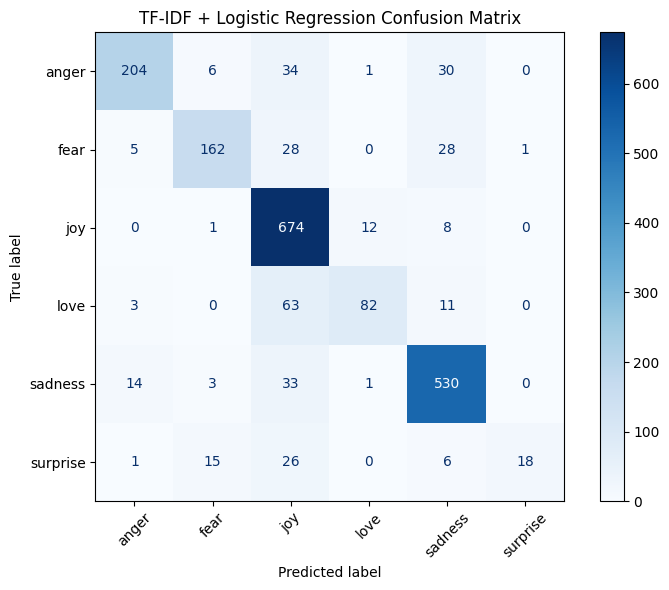


Model saved successfully.
Vectorizer saved successfully.
STEP 7 COMPLETED SUCCESSFULLY!


In [8]:

# STEP 7: TF-IDF + Logistic Regression Baseline

import os
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Define project paths
PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load encoded datasets
train_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "train_encoded.csv")
)
val_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "validation_encoded.csv")
)
test_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "test_encoded.csv")
)

X_train_text = train_df["text"].astype(str)
y_train = train_df["label_encoded"]

X_val_text = val_df["text"].astype(str)
y_val = val_df["label_encoded"]

X_test_text = test_df["text"].astype(str)
y_test = test_df["label_encoded"]

# 3. Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Learn vocabulary only from training data
X_train = tfidf.fit_transform(X_train_text)

# Transform validation and test data
X_val = tfidf.transform(X_val_text)
X_test = tfidf.transform(X_test_text)

print("TF-IDF feature shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# 4. Build the Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 5. Train the model
print("\nTraining Logistic Regression model...")
model.fit(X_train, y_train)

# 6. Evaluate on validation data
val_predictions = model.predict(X_val)

val_accuracy = accuracy_score(
    y_val, val_predictions
)

print("\nValidation accuracy:",
      round(val_accuracy, 4))

# 7. Evaluate on test data
test_predictions = model.predict(X_test)

test_accuracy = accuracy_score(
    y_test, test_predictions
)

print("\nTest accuracy:",
      round(test_accuracy, 4))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        labels=list(range(len(joblib.load(
            os.path.join(MODEL_DIR, "label_encoder.pkl")
        ).classes_))),
        target_names=joblib.load(
            os.path.join(MODEL_DIR, "label_encoder.pkl")
        ).classes_,
        zero_division=0
    )
)

# 8. Plot and save the confusion matrix
label_encoder = joblib.load(
    os.path.join(MODEL_DIR, "label_encoder.pkl")
)

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=list(range(len(label_encoder.classes_))),
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("TF-IDF + Logistic Regression Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "baseline_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. Save the trained model and vectorizer
joblib.dump(
    model,
    os.path.join(MODEL_DIR, "baseline_model.pkl")
)

joblib.dump(
    tfidf,
    os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl")
)

# 10. Save baseline results
results = {
    "model": "TF-IDF + Logistic Regression",
    "validation_accuracy": float(val_accuracy),
    "test_accuracy": float(test_accuracy)
}

pd.DataFrame([results]).to_csv(
    os.path.join(OUTPUT_DIR, "baseline_results.csv"),
    index=False
)

print("\nModel saved successfully.")
print("Vectorizer saved successfully.")
print("STEP 7 COMPLETED SUCCESSFULLY!")


Build and Train the LSTM Model

Training data: (16000, 50)
Validation data: (2000, 50)
Vocabulary size: 15214
Number of emotion classes: 6

LSTM Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ word_embedding (Embedding)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_layer (LSTM)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emotion_output (Dense)          │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Starting LSTM training...
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 25s 88ms/step - accuracy: 0.4888 - loss: 1.2933 - val_accuracy: 0.7235 - val_loss: 0.7680
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 41s 91ms/step - accuracy: 0.8239 - loss: 0.4963 - val_accuracy: 0.8730 - val_loss: 0.3867
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 81ms/step - accuracy: 0.9358 - loss: 0.1994 - val_accuracy: 0.8960 - val_loss: 0.3707
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 22s 88ms/step - accuracy: 0.9651 - loss: 0.1106 - val_accuracy: 0.9025 - val_loss: 0.3452
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 83ms/step - accuracy: 0.9753 - loss: 0.0832 - val_accuracy: 0.8855 - val_loss: 0.4671
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 42s 87ms/step - accuracy: 0.9784 - loss: 0.0650 - val_accuracy: 0.9020 - val_loss: 0.4183
Epoch 7/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 42s 91ms/step - accuracy: 0.9746 - loss: 0.0805 - val_accuracy: 0.9070 - val_loss: 0.3271
Epoch 8/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 81ms/step - accurac

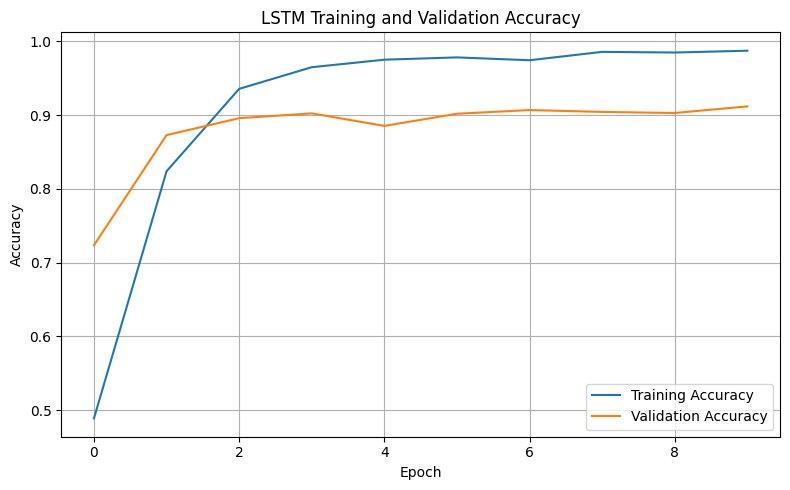

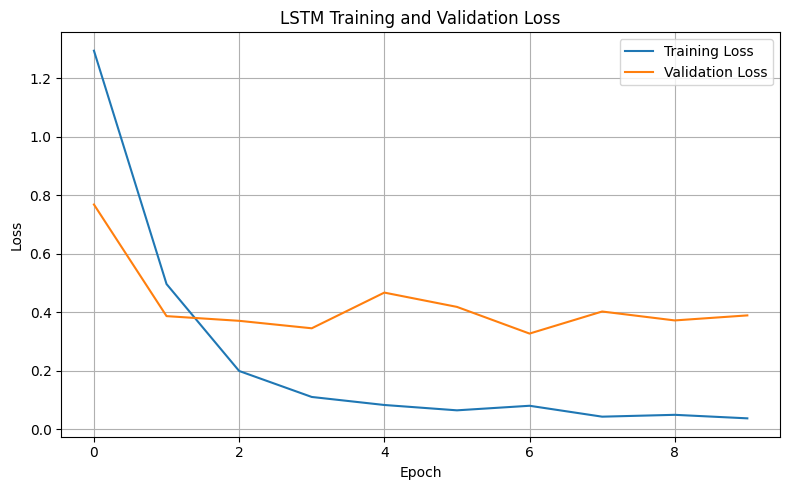


Best epoch: 7
Best validation accuracy: 0.907

Saved LSTM model: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/models/lstm_emotion_model.keras
Training history and graphs saved.
STEP 8 COMPLETED SUCCESSFULLY!


In [9]:
# STEP 8: Build and Train the LSTM Model

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 1. Define project paths
PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load tokenized data from Step 6
data = np.load(
    os.path.join(PROCESSED_DIR, "tokenized_data.npz")
)

X_train = data["X_train"]
y_train = data["y_train"]
X_val = data["X_val"]
y_val = data["y_val"]

# 3. Load model configuration
with open(
    os.path.join(MODEL_DIR, "model_config.json"), "r"
) as file:
    config = json.load(file)

VOCAB_SIZE = config["vocab_size"]
MAX_LEN = config["max_len"]
NUM_CLASSES = config["num_classes"]

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Vocabulary size:", VOCAB_SIZE)
print("Number of emotion classes:", NUM_CLASSES)

# 4. Build the LSTM model
model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True,
        name="word_embedding"
    ),

    LSTM(
        64,
        name="lstm_layer"
    ),

    Dropout(0.3),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        NUM_CLASSES,
        activation="softmax",
        name="emotion_output"
    )
])

# 5. Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Display model architecture
print("\nLSTM Model Architecture:")
model.summary()

# 7. Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# 8. Train the model
print("\nStarting LSTM training...")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

# 9. Save the trained model
model_path = os.path.join(
    MODEL_DIR, "lstm_emotion_model.keras"
)

model.save(model_path)

# 10. Save training history
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(OUTPUT_DIR, "lstm_training_history.csv"),
    index=False
)

# 11. Plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "lstm_accuracy.png"),
    dpi=300
)
plt.show()

# 12. Plot loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "lstm_loss.png"),
    dpi=300
)
plt.show()

# 13. Display final validation metrics
best_epoch = np.argmin(history.history["val_loss"])

print("\nBest epoch:", best_epoch + 1)
print(
    "Best validation accuracy:",
    round(history.history["val_accuracy"][best_epoch], 4)
)

print("\nSaved LSTM model:", model_path)
print("Training history and graphs saved.")
print("STEP 8 COMPLETED SUCCESSFULLY!")


Build and train the BiLSTM model

Training data: (16000, 50)
Validation data: (2000, 50)
Vocabulary size: 15214
Number of classes: 6

BiLSTM Model Architecture:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ word_embedding (Embedding)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_lstm              │ ?                      │   0 (unbuilt) │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emotion_output (Dense)          │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Starting BiLSTM training...
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 50s 162ms/step - accuracy: 0.5071 - loss: 1.2376 - val_accuracy: 0.7285 - val_loss: 0.7260
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 34s 137ms/step - accuracy: 0.8533 - loss: 0.4173 - val_accuracy: 0.8900 - val_loss: 0.3178
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 36s 145ms/step - accuracy: 0.9477 - loss: 0.1623 - val_accuracy: 0.9030 - val_loss: 0.3123
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 39s 155ms/step - accuracy: 0.9657 - loss: 0.1011 - val_accuracy: 0.9075 - val_loss: 0.3070
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 35s 139ms/step - accuracy: 0.9788 - loss: 0.0642 - val_accuracy: 0.9090 - val_loss: 0.3582
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 41s 138ms/step - accuracy: 0.9817 - loss: 0.0544 - val_accuracy: 0.9065 - val_loss: 0.3514
Epoch 7/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 35s 139ms/step - accuracy: 0.9847 - loss: 0.0463 - val_accuracy: 0.9000 - val_loss: 0.3342


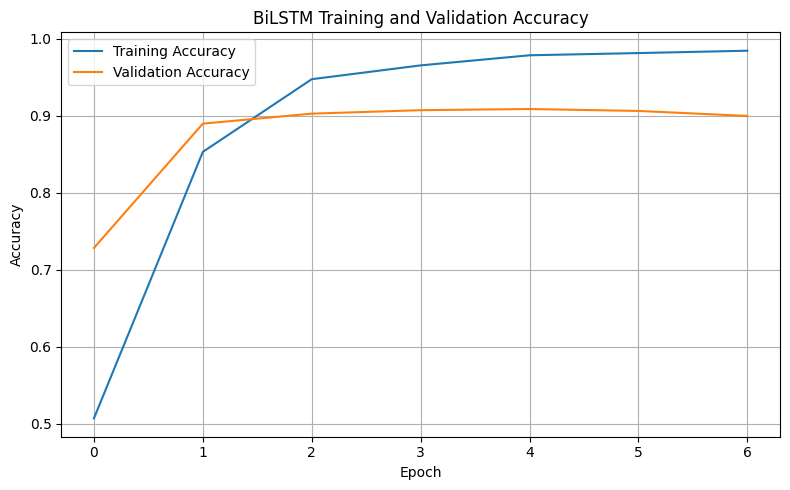

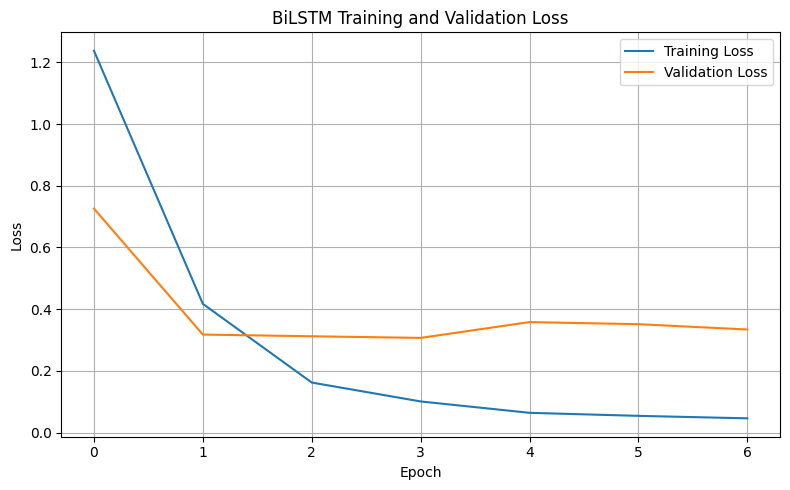


Best epoch: 4
Best validation accuracy: 0.9075
Best validation loss: 0.307

Saved model: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/models/bilstm_emotion_model.keras
STEP 9 COMPLETED SUCCESSFULLY!


In [10]:

# STEP 9: Build and Train the BiLSTM Model

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    Bidirectional,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

# 1. Define project paths
PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load tokenized data from Step 6
data = np.load(
    os.path.join(PROCESSED_DIR, "tokenized_data.npz")
)

X_train = data["X_train"]
y_train = data["y_train"]
X_val = data["X_val"]
y_val = data["y_val"]

# 3. Load model configuration
with open(
    os.path.join(MODEL_DIR, "model_config.json"), "r"
) as file:
    config = json.load(file)

VOCAB_SIZE = config["vocab_size"]
MAX_LEN = config["max_len"]
NUM_CLASSES = config["num_classes"]

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Vocabulary size:", VOCAB_SIZE)
print("Number of classes:", NUM_CLASSES)

# 4. Build the BiLSTM model
model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True,
        name="word_embedding"
    ),

    Bidirectional(
        LSTM(64),
        name="bidirectional_lstm"
    ),

    Dropout(0.3),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        NUM_CLASSES,
        activation="softmax",
        name="emotion_output"
    )
])

# 5. Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Display architecture
print("\nBiLSTM Model Architecture:")
model.summary()

# 7. Configure early stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# 8. Train the model
print("\nStarting BiLSTM training...")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

# 9. Save the trained model
model_path = os.path.join(
    MODEL_DIR, "bilstm_emotion_model.keras"
)

model.save(model_path)

# 10. Save training history
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(OUTPUT_DIR, "bilstm_training_history.csv"),
    index=False
)

# 11. Plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("BiLSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "bilstm_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 12. Plot loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("BiLSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "bilstm_loss.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 13. Report best validation performance
best_epoch = int(np.argmin(history.history["val_loss"]))

print("\nBest epoch:", best_epoch + 1)
print(
    "Best validation accuracy:",
    round(history.history["val_accuracy"][best_epoch], 4)
)
print(
    "Best validation loss:",
    round(history.history["val_loss"][best_epoch], 4)
)

print("\nSaved model:", model_path)
print("STEP 9 COMPLETED SUCCESSFULLY!")


Evaluate and Compare All Models

Test samples: 2000
Emotion classes: ['anger', 'fear', 'joy', 'love', 'sadness', 'surprise']
Test data loaded successfully!

All three trained models loaded successfully!

Predictions generated successfully!

MODEL: TF-IDF + Logistic Regression
Accuracy: 0.835
Macro Precision: 0.8694
Macro Recall: 0.6892
Macro F1-score: 0.7373

Classification Report:
              precision    recall  f1-score   support

       anger     0.8987    0.7418    0.8127       275
        fear     0.8663    0.7232    0.7883       224
         joy     0.7855    0.9698    0.8680       695
        love     0.8542    0.5157    0.6431       159
     sadness     0.8646    0.9122    0.8878       581
    surprise     0.9474    0.2727    0.4235        66

    accuracy                         0.8350      2000
   macro avg     0.8694    0.6892    0.7373      2000
weighted avg     0.8439    0.8350    0.8247      2000


MODEL: LSTM
Accuracy: 0.9105
Macro Precision: 0.8645
Macro Recall: 0.8819
Macro F1-score: 0.8719

Classi

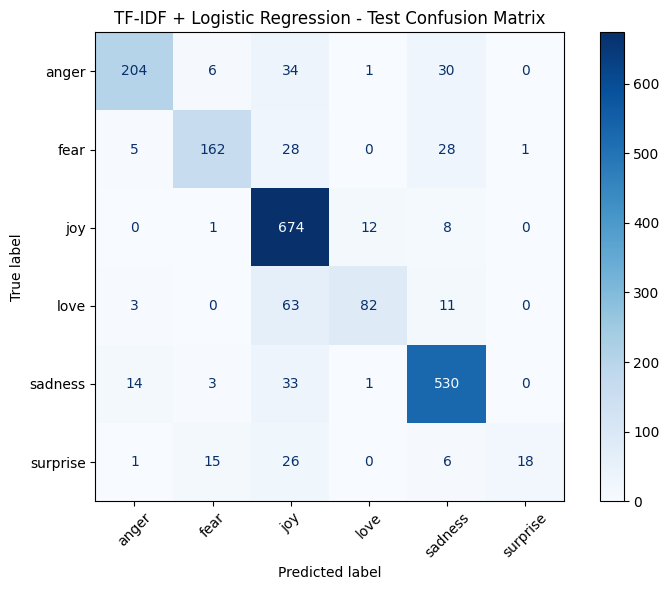

Saved: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/outputs/baseline_confusion_matrix_test.png


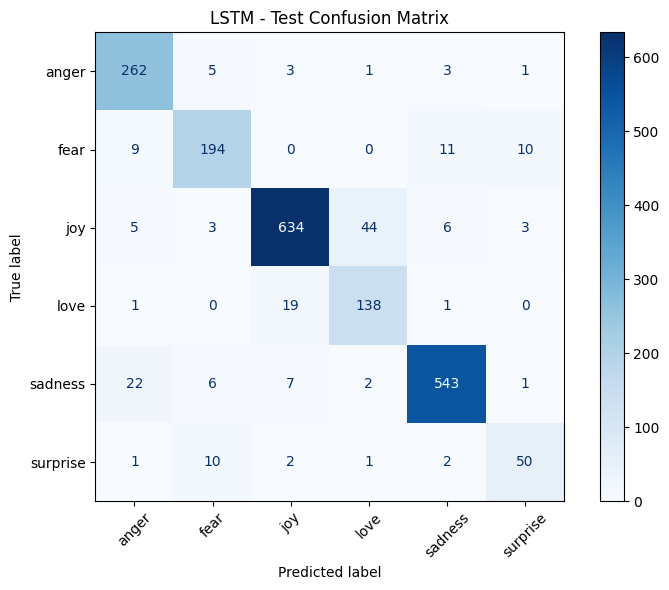

Saved: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/outputs/lstm_confusion_matrix_test.png


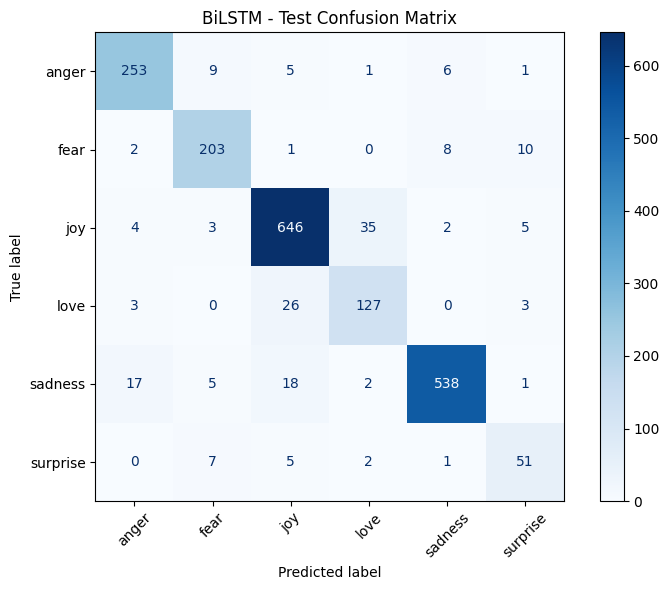

Saved: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/outputs/bilstm_confusion_matrix_test.png


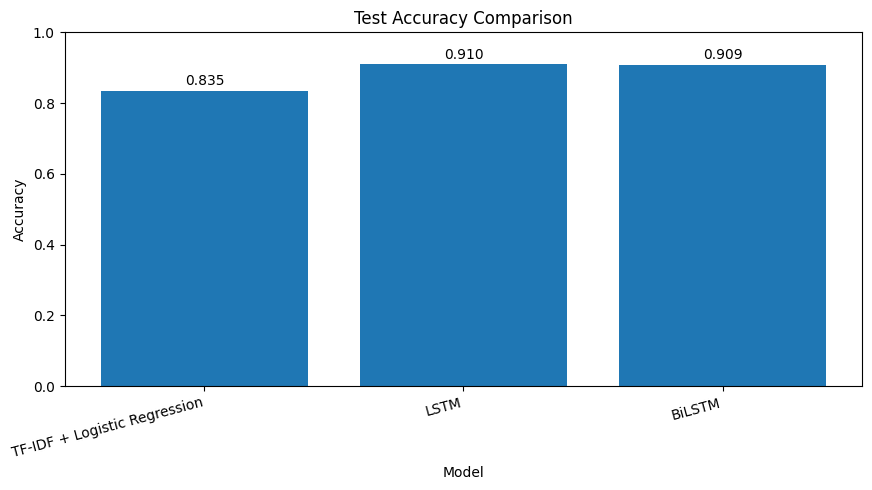

Saved: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/outputs/model_accuracy_comparison.png


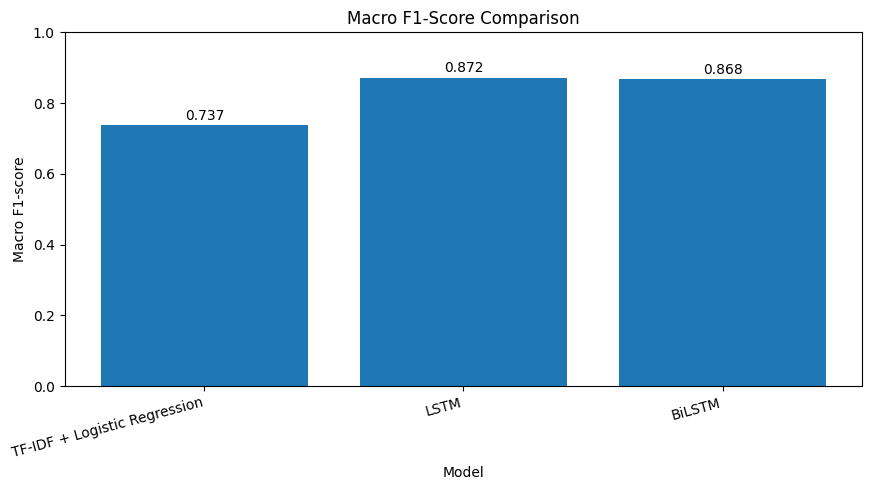

Saved: /content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/outputs/model_f1_comparison.png

STEP 10 COMPLETED SUCCESSFULLY!
Best model by Macro F1-score: LSTM
Best Macro F1-score: 0.8719
Its test accuracy: 0.9105

All evaluation files saved in:
/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL/outputs


In [11]:

# STEP 10: EVALUATE AND COMPARE ALL THREE MODELS

import os
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_recall_fscore_support,
    ConfusionMatrixDisplay
)

# --------------------------------------------------
# 1. DEFINE PROJECT PATHS
# --------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# --------------------------------------------------
# 2. LOAD TEST DATA
# --------------------------------------------------

data = np.load(
    os.path.join(PROCESSED_DIR, "tokenized_data.npz")
)

X_test = data["X_test"]
y_test = data["y_test"]

test_df = pd.read_csv(
    os.path.join(PROCESSED_DIR, "test_encoded.csv")
)

# Confirm that both test datasets have matching labels
if not np.array_equal(
    y_test,
    test_df["label_encoded"].to_numpy(dtype=np.int32)
):
    raise ValueError(
        "Test labels do not match. Please check Steps 4–6."
    )

label_encoder = joblib.load(
    os.path.join(MODEL_DIR, "label_encoder.pkl")
)

class_names = label_encoder.classes_
labels = np.arange(len(class_names))

print("Test samples:", len(y_test))
print("Emotion classes:", list(class_names))
print("Test data loaded successfully!")

# --------------------------------------------------
# 3. LOAD TRAINED MODELS
# --------------------------------------------------

baseline_model = joblib.load(
    os.path.join(MODEL_DIR, "baseline_model.pkl")
)

tfidf = joblib.load(
    os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl")
)

lstm_model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "lstm_emotion_model.keras")
)

bilstm_model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "bilstm_emotion_model.keras")
)

print("\nAll three trained models loaded successfully!")

# --------------------------------------------------
# 4. GENERATE PREDICTIONS
# --------------------------------------------------

# Baseline: TF-IDF + Logistic Regression
X_test_text = test_df["text"].fillna("").astype(str)
X_test_tfidf = tfidf.transform(X_test_text)

baseline_predictions = baseline_model.predict(X_test_tfidf)

# LSTM
lstm_probabilities = lstm_model.predict(
    X_test, verbose=0
)
lstm_predictions = np.argmax(lstm_probabilities, axis=1)

# BiLSTM
bilstm_probabilities = bilstm_model.predict(
    X_test, verbose=0
)
bilstm_predictions = np.argmax(bilstm_probabilities, axis=1)

predictions = {
    "TF-IDF + Logistic Regression": baseline_predictions,
    "LSTM": lstm_predictions,
    "BiLSTM": bilstm_predictions
}

print("\nPredictions generated successfully!")

# --------------------------------------------------
# 5. CALCULATE EVALUATION METRICS
# --------------------------------------------------

results = []
report_text = []

for model_name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    macro_p, macro_r, macro_f1, _ = (
        precision_recall_fscore_support(
            y_test,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0
        )
    )

    weighted_p, weighted_r, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_test,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0
        )
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro_Precision": macro_p,
        "Macro_Recall": macro_r,
        "Macro_F1": macro_f1,
        "Weighted_Precision": weighted_p,
        "Weighted_Recall": weighted_r,
        "Weighted_F1": weighted_f1
    })

    report = classification_report(
        y_test,
        y_pred,
        labels=labels,
        target_names=class_names,
        zero_division=0,
        digits=4
    )

    report_text.append(
        f"\n{'=' * 65}\n"
        f"MODEL: {model_name}\n"
        f"{'=' * 65}\n"
        f"Accuracy: {accuracy:.4f}\n\n"
        f"{report}\n"
    )

    print(f"\n{'=' * 55}")
    print("MODEL:", model_name)
    print(f"{'=' * 55}")
    print("Accuracy:", round(accuracy, 4))
    print("Macro Precision:", round(macro_p, 4))
    print("Macro Recall:", round(macro_r, 4))
    print("Macro F1-score:", round(macro_f1, 4))
    print("\nClassification Report:")
    print(report)

# --------------------------------------------------
# 6. SAVE MODEL COMPARISON TABLE
# --------------------------------------------------

results_df = pd.DataFrame(results)

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

print("\nMODEL COMPARISON TABLE")
print(
    results_df.round(4).to_string(index=False)
)

# --------------------------------------------------
# 7. SAVE CLASSIFICATION REPORTS
# --------------------------------------------------

report_path = os.path.join(
    OUTPUT_DIR, "classification_reports.txt"
)

with open(report_path, "w", encoding="utf-8") as file:
    file.write("\n".join(report_text))

print("\nClassification reports saved to:", report_path)

# --------------------------------------------------
# 8. GENERATE CONFUSION MATRICES
# --------------------------------------------------

confusion_files = {
    "TF-IDF + Logistic Regression":
        "baseline_confusion_matrix_test.png",
    "LSTM":
        "lstm_confusion_matrix_test.png",
    "BiLSTM":
        "bilstm_confusion_matrix_test.png"
}

for model_name, y_pred in predictions.items():

    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=labels,
        display_labels=class_names,
        xticks_rotation=45,
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"{model_name} - Test Confusion Matrix")
    plt.tight_layout()

    graph_path = os.path.join(
        OUTPUT_DIR, confusion_files[model_name]
    )

    plt.savefig(
        graph_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", graph_path)

# --------------------------------------------------
# 9. COMPARE MODEL ACCURACY
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Test Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")

for i, value in enumerate(results_df["Accuracy"]):
    plt.text(
        i,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

accuracy_path = os.path.join(
    OUTPUT_DIR, "model_accuracy_comparison.png"
)

plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", accuracy_path)

# --------------------------------------------------
# 10. COMPARE MACRO F1-SCORE
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Macro_F1"]
)

plt.title("Macro F1-Score Comparison")
plt.xlabel("Model")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")

for i, value in enumerate(results_df["Macro_F1"]):
    plt.text(
        i,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

f1_path = os.path.join(
    OUTPUT_DIR, "model_f1_comparison.png"
)

plt.savefig(f1_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", f1_path)

# --------------------------------------------------
# 11. IDENTIFY THE BEST MODEL
# --------------------------------------------------

best_model = results_df.loc[
    results_df["Macro_F1"].idxmax()
]

print("\n" + "=" * 55)
print("STEP 10 COMPLETED SUCCESSFULLY!")
print("=" * 55)

print("Best model by Macro F1-score:", best_model["Model"])
print("Best Macro F1-score:", round(best_model["Macro_F1"], 4))
print("Its test accuracy:", round(best_model["Accuracy"], 4))

print("\nAll evaluation files saved in:")
print(OUTPUT_DIR)


Build the Emotion Prediction System *

In [13]:

# STEP 11: EMOTION PREDICTION SYSTEM

import os
import re
import json
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.preprocessing.sequence import pad_sequences

# --------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Text_NLP/Emotion_Detection_NLP_DL"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR, "bilstm_emotion_model.keras"
)

TOKENIZER_PATH = os.path.join(
    MODEL_DIR, "tokenizer.pkl"
)

ENCODER_PATH = os.path.join(
    MODEL_DIR, "label_encoder.pkl"
)

CONFIG_PATH = os.path.join(
    MODEL_DIR, "model_config.json"
)

# --------------------------------------------------
# 2. CHECK REQUIRED FILES
# --------------------------------------------------

required_files = [
    MODEL_PATH,
    TOKENIZER_PATH,
    ENCODER_PATH,
    CONFIG_PATH
]

for path in required_files:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Please complete Steps 5, 6, and 9 first."
        )

# --------------------------------------------------
# 3. LOAD TRAINED MODEL AND TOOLS
# --------------------------------------------------

model = tf.keras.models.load_model(MODEL_PATH)
tokenizer = joblib.load(TOKENIZER_PATH)
label_encoder = joblib.load(ENCODER_PATH)

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    config = json.load(file)

MAX_LEN = config["max_len"]
class_names = label_encoder.classes_

print("BiLSTM model loaded successfully!")
print("Emotion categories:", list(class_names))
print("Maximum sequence length:", MAX_LEN)

# --------------------------------------------------
# 4. CLEAN USER TEXT
# --------------------------------------------------

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# --------------------------------------------------
# 5. PREDICT EMOTION
# --------------------------------------------------

def predict_emotion(text):

    if not text or not text.strip():
        print("Please enter a valid sentence.")
        return None

    cleaned_text = clean_text(text)

    if not cleaned_text:
        print("No usable English text was found.")
        return None

    # Convert text into numerical sequences
    sequence = tokenizer.texts_to_sequences([cleaned_text])

    # Pad sequence to the training length
    padded_sequence = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Predict probabilities for all emotion categories
    probabilities = model.predict(
        padded_sequence, verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_emotion = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    confidence = float(probabilities[predicted_index]) * 100

    # Display prediction
    print("\n" + "=" * 45)
    print("EMOTION PREDICTION RESULT")
    print("=" * 45)
    print("Input text:", text)
    print("Predicted emotion:", predicted_emotion.upper())
    print(f"Model confidence: {confidence:.2f}%")

    print("\nEmotion probability scores:")

    for i in np.argsort(probabilities)[::-1]:
        print(
            f"{class_names[i]:<12}: "
            f"{probabilities[i] * 100:.2f}%"
        )

    print("=" * 45)

    return {
        "text": text,
        "cleaned_text": cleaned_text,
        "predicted_emotion": predicted_emotion,
        "confidence_percent": round(confidence, 2),
        "probabilities": {
            class_names[i]: round(
                float(probabilities[i]) * 100, 2
            )
            for i in range(len(class_names))
        }
    }

# --------------------------------------------------
# 6. TEST WITH SAMPLE SENTENCES
# --------------------------------------------------

sample_sentences = [
    "I am very happy today",
    "I feel so sad and lonely",
    "I am really angry about this",
    "I am afraid of what might happen",
    "I love spending time with you",
    "Wow, I did not expect that!"
]

print("\nSAMPLE PREDICTIONS")

sample_results = []

for sentence in sample_sentences:
    result = predict_emotion(sentence)
    if result is not None:
        sample_results.append(result)

# Save sample predictions
sample_df = pd.DataFrame([
    {
        "text": result["text"],
        "predicted_emotion": result["predicted_emotion"],
        "confidence_percent": result["confidence_percent"]
    }
    for result in sample_results
])

sample_output_path = os.path.join(
    OUTPUT_DIR, "sample_predictions.csv"
)

sample_df.to_csv(sample_output_path, index=False)

print("\nSample predictions saved to:")
print(sample_output_path)

# --------------------------------------------------
# 7. ENTER YOUR OWN SENTENCE
# --------------------------------------------------

user_text = input(
    "\nEnter a sentence to detect its emotion: "
)

user_result = predict_emotion(user_text)

# Save the user's prediction
if user_result is not None:

    user_output_path = os.path.join(
        OUTPUT_DIR, "user_prediction.csv"
    )

    pd.DataFrame([{
        "text": user_result["text"],
        "predicted_emotion": user_result["predicted_emotion"],
        "confidence_percent": user_result["confidence_percent"]
    }]).to_csv(
        user_output_path,
        index=False
    )

    print("\nUser prediction saved to:")
    print(user_output_path)

print("\nSTEP 11 COMPLETED SUCCESSFULLY!")


BiLSTM model loaded successfully!
Emotion categories: ['anger', 'fear', 'joy', 'love', 'sadness', 'surprise']
Maximum sequence length: 50

SAMPLE PREDICTIONS

EMOTION PREDICTION RESULT
Input text: I am very happy today
Predicted emotion: JOY
Model confidence: 98.89%

Emotion probability scores:
joy         : 98.89%
love        : 0.74%
sadness     : 0.25%
anger       : 0.06%
fear        : 0.04%
surprise    : 0.02%

EMOTION PREDICTION RESULT
Input text: I feel so sad and lonely
Predicted emotion: SADNESS
Model confidence: 99.98%

Emotion probability scores:
sadness     : 99.98%
joy         : 0.01%
anger       : 0.01%
fear        : 0.00%
love        : 0.00%
surprise    : 0.00%

EMOTION PREDICTION RESULT
Input text: I am really angry about this
Predicted emotion: ANGER
Model confidence: 93.52%

Emotion probability scores:
anger       : 93.52%
fear        : 5.14%
love        : 0.67%
sadness     : 0.54%
surprise    : 0.06%
joy         : 0.06%

EMOTION PREDICTION RESULT
Input text: I am afrai